<div align="center">

# **Student Performance Analysis.**

<img src= "https://i.postimg.cc/rsv2bS2r/Designer.png"
width="800">

</div>


#**Project Title:   Student Performance Analysis using Exploratory Data Analysis (EDA)**
## Project Overview

The Student Performance Analysis project aims to explore and analyze students' academic performance using Python and data analysis libraries. The project uses a student performance dataset containing information such as gender, parental education level, test preparation course, and mathematics, reading, and writing scores.


The main objective is to identify patterns, trends, and relationships that may influence students' academic performance. Using Pandas and NumPy, the data will be cleaned and analyzed, while Matplotlib and Seaborn will be used to create visualizations and discover meaningful insights.


This project involves analyzing average subject scores, comparing performance across different student groups, examining relationships between subjects, and identifying factors associated with higher or lower scores.


The findings can help educators better understand student performance patterns and support data-driven decisions to improve learning outcomes.

**Technologies Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab.

**Project Type:** Exploratory Data Analysis (EDA)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore


In [3]:
df = pd.read_csv(r"/content/student_performance_1_million.csv")

In [5]:
df

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
0,1,15,Female,High School,12.4,88.4,64.6,No,Yes,No,6.2,49.6,Average
1,2,21,Female,High School,27.4,77.1,64.1,No,Yes,No,7.6,57.7,Average
2,3,20,Male,High School,4.5,76.4,59.0,No,Yes,No,7.1,49.5,Average
3,4,18,Male,Bachelor's,9.7,81.6,65.6,Yes,Yes,No,6.0,64.5,Good
4,5,18,Male,Master's,6.5,100.0,100.0,No,Yes,Yes,6.5,68.0,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,999996,21,Female,Below High School,8.0,99.0,96.8,No,Yes,No,7.6,59.7,Average
999996,999997,18,Female,Bachelor's,14.1,97.3,67.5,No,Yes,No,7.3,50.5,Average
999997,999998,22,Male,High School,4.1,93.8,88.8,Yes,Yes,No,6.7,50.8,Average
999998,999999,15,Female,High School,10.7,86.6,60.6,No,Yes,Yes,7.2,56.9,Average


### About the dataset

In [6]:
print(f'Shape Of the Dataset: {df.shape}')

Shape Of the Dataset: (1000000, 13)


In [7]:
print(f'Columns of the Dataset:{df.columns}')

Columns of the Dataset:Index(['student_id', 'age', 'gender', 'parental_education',
       'study_hours_per_week', 'attendance_rate', 'previous_score', 'tutoring',
       'internet_access', 'extracurricular_activities', 'sleep_hours_per_day',
       'exam_score', 'performance_level'],
      dtype='object')


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   student_id                  1000000 non-null  int64  
 1   age                         1000000 non-null  int64  
 2   gender                      1000000 non-null  object 
 3   parental_education          1000000 non-null  object 
 4   study_hours_per_week        1000000 non-null  float64
 5   attendance_rate             1000000 non-null  float64
 6   previous_score              1000000 non-null  float64
 7   tutoring                    1000000 non-null  object 
 8   internet_access             1000000 non-null  object 
 9   extracurricular_activities  1000000 non-null  object 
 10  sleep_hours_per_day         1000000 non-null  float64
 11  exam_score                  1000000 non-null  float64
 12  performance_level           1000000 non-null  object 
dty

In [9]:
df.describe()

,student_id,age,study_hours_per_week,attendance_rate,previous_score,sleep_hours_per_day,exam_score
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,500000.500000,18.497430,10.986195,81.659075,67.911771,7.099272,51.242710
std,288675.278933,2.290776,7.313462,11.316425,14.772153,1.198561,11.500566
min,1.000000,15.000000,0.000000,35.000000,0.000000,3.000000,0.000000
25%,250000.750000,16.000000,5.500000,73.900000,57.900000,6.300000,43.500000
50%,500000.500000,18.000000,9.400000,82.000000,68.000000,7.100000,51.200000
75%,750000.250000,20.000000,14.700000,90.100000,78.100000,7.900000,58.900000
max,1000000.000000,22.000000,40.000000,100.000000,100.000000,12.000000,100.000000


In [10]:
# First 5 rows
df.head()

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
0,1,15,Female,High School,12.4,88.4,64.6,No,Yes,No,6.2,49.6,Average
1,2,21,Female,High School,27.4,77.1,64.1,No,Yes,No,7.6,57.7,Average
2,3,20,Male,High School,4.5,76.4,59.0,No,Yes,No,7.1,49.5,Average
3,4,18,Male,Bachelor's,9.7,81.6,65.6,Yes,Yes,No,6.0,64.5,Good
4,5,18,Male,Master's,6.5,100.0,100.0,No,Yes,Yes,6.5,68.0,Good


In [11]:
# Last 5 rows
df.tail()

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
999995,999996,21,Female,Below High School,8.0,99.0,96.8,No,Yes,No,7.6,59.7,Average
999996,999997,18,Female,Bachelor's,14.1,97.3,67.5,No,Yes,No,7.3,50.5,Average
999997,999998,22,Male,High School,4.1,93.8,88.8,Yes,Yes,No,6.7,50.8,Average
999998,999999,15,Female,High School,10.7,86.6,60.6,No,Yes,Yes,7.2,56.9,Average
999999,1000000,16,Female,Diploma,19.6,61.9,83.6,No,Yes,No,6.6,49.3,Average


In [12]:
df.sample(5)

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
276919,276920,17,Male,Below High School,7.6,96.9,90.1,No,Yes,No,7.6,63.6,Good
235567,235568,20,Female,High School,15.2,65.9,61.0,No,Yes,No,7.3,30.4,Needs Improvement
208012,208013,19,Male,High School,4.6,76.7,51.3,No,Yes,No,9.4,57.3,Average
622036,622037,20,Male,Diploma,20.6,70.4,88.5,Yes,No,Yes,7.6,62.9,Good
59782,59783,22,Female,Master's,3.7,68.9,65.9,Yes,Yes,Yes,7.1,54.3,Average


In [13]:
df.dtypes

,0
student_id,int64
age,int64
gender,object
parental_education,object
study_hours_per_week,float64
attendance_rate,float64
previous_score,float64
tutoring,object
internet_access,object
extracurricular_activities,object


## Data Cleaning

In [14]:
df.isna()

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
0,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,False,False,False,False,False,False,False,False,False,False,False,False,False
999996,False,False,False,False,False,False,False,False,False,False,False,False,False
999997,False,False,False,False,False,False,False,False,False,False,False,False,False
999998,False,False,False,False,False,False,False,False,False,False,False,False,False


In [15]:
df.isna().sum()

,0
student_id,0
age,0
gender,0
parental_education,0
study_hours_per_week,0
attendance_rate,0
previous_score,0
tutoring,0
internet_access,0
extracurricular_activities,0


In [16]:
(df.isnull().sum() / len(df)) * 100

,0
student_id,0.0
age,0.0
gender,0.0
parental_education,0.0
study_hours_per_week,0.0
attendance_rate,0.0
previous_score,0.0
tutoring,0.0
internet_access,0.0
extracurricular_activities,0.0


## Check  Duplicate Rows

In [17]:
df.duplicated().sum()

np.int64(0)

## Check unique values

In [19]:
df.nunique()

,0
student_id,1000000
age,8
gender,3
parental_education,5
study_hours_per_week,401
attendance_rate,648
previous_score,927
tutoring,2
internet_access,2
extracurricular_activities,2


## Check Categorical Values

In [ ]:
df["Gender"].value_counts()

In [ ]:
df["Academic_Work_Impact"].value_counts()

In [20]:
### Mean , Median , Mode
df.select_dtypes(include=np.number).mean()

,0
student_id,500000.500000
age,18.497430
study_hours_per_week,10.986195
attendance_rate,81.659075
previous_score,67.911771
sleep_hours_per_day,7.099272
exam_score,51.242710


In [21]:
df.select_dtypes(include=np.number).median()

,0
student_id,500000.5
age,18.0
study_hours_per_week,9.4
attendance_rate,82.0
previous_score,68.0
sleep_hours_per_day,7.1
exam_score,51.2


In [22]:
df.select_dtypes(include=np.number).mode()

,student_id,age,study_hours_per_week,attendance_rate,previous_score,sleep_hours_per_day,exam_score
0,1,15.0,6.1,100.0,100.0,7.0,51.6
1,2,NaN,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
999995,999996,NaN,NaN,NaN,NaN,NaN,NaN
999996,999997,NaN,NaN,NaN,NaN,NaN,NaN
999997,999998,NaN,NaN,NaN,NaN,NaN,NaN
999998,999999,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
df

,student_id,age,gender,parental_education,study_hours_per_week,attendance_rate,previous_score,tutoring,internet_access,extracurricular_activities,sleep_hours_per_day,exam_score,performance_level
0,1,15,Female,High School,12.4,88.4,64.6,No,Yes,No,6.2,49.6,Average
1,2,21,Female,High School,27.4,77.1,64.1,No,Yes,No,7.6,57.7,Average
2,3,20,Male,High School,4.5,76.4,59.0,No,Yes,No,7.1,49.5,Average
3,4,18,Male,Bachelor's,9.7,81.6,65.6,Yes,Yes,No,6.0,64.5,Good
4,5,18,Male,Master's,6.5,100.0,100.0,No,Yes,Yes,6.5,68.0,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,999996,21,Female,Below High School,8.0,99.0,96.8,No,Yes,No,7.6,59.7,Average
999996,999997,18,Female,Bachelor's,14.1,97.3,67.5,No,Yes,No,7.3,50.5,Average
999997,999998,22,Male,High School,4.1,93.8,88.8,Yes,Yes,No,6.7,50.8,Average
999998,999999,15,Female,High School,10.7,86.6,60.6,No,Yes,Yes,7.2,56.9,Average


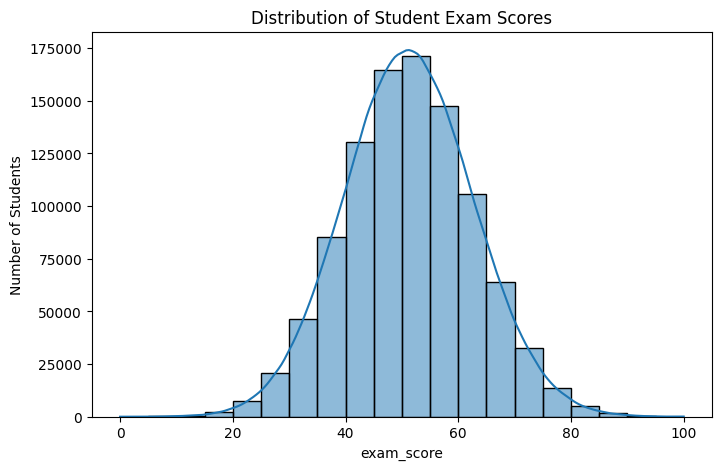

In [24]:
# Distribution of exam scores
plt.figure(figsize=(8, 5))
sns.histplot(df['exam_score'], bins=20, kde=True)
plt.title("Distribution of Student Exam Scores")
plt.xlabel("exam_score")
plt.ylabel("Number of Students")
plt.show()


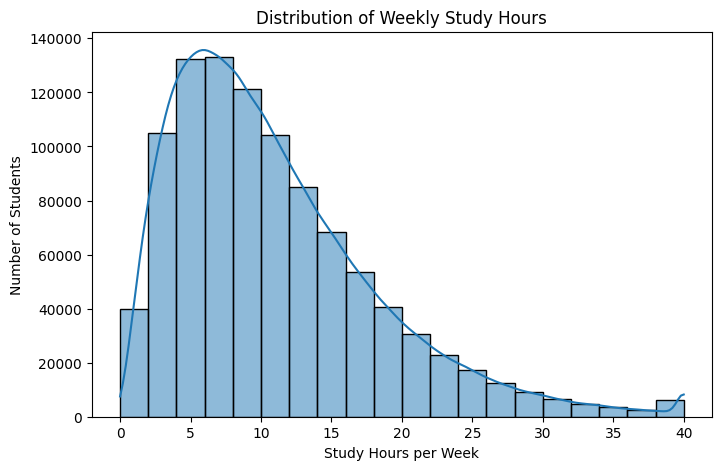

In [25]:
# Distribution of study hours
plt.figure(figsize=(8, 5))
sns.histplot(df['study_hours_per_week'], bins=20, kde=True)
plt.title("Distribution of Weekly Study Hours")
plt.xlabel("Study Hours per Week")
plt.ylabel("Number of Students")
plt.show()


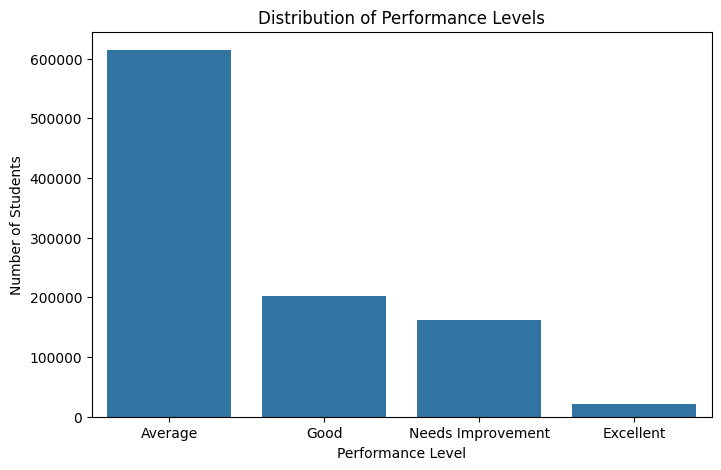

In [26]:
# Distribution of performance levels
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='performance_level')
plt.title("Distribution of Performance Levels")
plt.xlabel("Performance Level")
plt.ylabel("Number of Students")
plt.show()